# Pré-processing et modélisation : prédiction de la bactériémie

## 1. Importation des données

In [1]:
import hashlib
import json

from datetime import datetime
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier, StackingClassifier)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.metrics import confusion_matrix, roc_curve

from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     TunedThresholdClassifierCV,
                                     cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, RobustScaler

from skopt import BayesSearchCV
from skopt.space import Categorical, Integer, Real
from skopt.callbacks import DeltaYStopper

import mlflow
from mlflow.models.signature import infer_signature

SEED = 42

In [2]:
###############################################################
# 0. Activer l environnement
# 
# 1. Lancer le serveur MLflow :
#    mlflow ui
#
# 2. MLflow crée automatiquement 'mlflow.db' dans le dossier courant
#    → C'est la base de données SQLite qui stocke :
#      - Les expériences (experiments)
#      - Les runs et leurs hyperparamètres
#      - Les métriques (accuracy, rmse...)
#      - Les tags
#    → Les modèles (artefacts) sont stockés dans mlartifacts/
#
# 3. L'interface web est accessible sur :
#    http://localhost:5000
#
# ⚠️  mlflow.db et mlartifacts/ sont dans .gitignore
#     → Ne jamais les pousser sur GitHub (trop lourds)
###############################################################

In [3]:
###############################################################
# CONNEXION AU SERVEUR MLFLOW
###############################################################
# On pointe vers le serveur local lancé avec 'mlflow ui'
# Tous les logs (params, métriques, modèles) seront envoyés
# vers mlflow.db à la racine du projet
###############################################################
mlflow.set_tracking_uri("http://localhost:5000")

###############################################################
# CRÉATION DE L'EXPÉRIENCE
###############################################################
# Une expérience = un groupe de runs liés au même objectif
# Si l'expérience n'existe pas, MLflow la crée automatiquement
# Visible dans l'UI sous : Experiments > bacteriemie prediction...
###############################################################
mlflow.set_experiment("bacteriemie prediction_finale2")


###############################################################
# IDENTIFIANT D'EXECUTION
###############################################################
# Les cellules d'un notebook se lancent une par une : garder un run
# parent ouvert sur plusieurs cellules laisserait des runs orphelins
# des qu'une cellule est relancee. On cree donc des runs plats, et
# c'est ce tag qui regroupe tous ceux d'une meme execution.
###############################################################
EXECUTION = datetime.now().strftime("%Y%m%d-%H%M")


def tags(etape: str, modele: str | None = None) -> dict:
    """Tags communs, pour filtrer et grouper dans l'interface MLflow."""
    t = {"execution": EXECUTION, "etape": etape, "seed": str(SEED)}
    if modele:
        t["modele"] = modele
    return t


print("execution :", EXECUTION)

execution : 20261021-1534


- [Polars](https://docs.pola.rs)
- [Sklearn](https://scikit-learn.org/stable/api/sklearn.html#)

In [4]:
pl.Config.set_tbl_cols(-1)   # afficher toutes les colonnes
pl.Config.set_tbl_rows(20)


polars.config.Config

In [5]:
data = "../data/bacteriemie.csv.gz"

# null_values="NA" : sans cela polars echoue sur la premiere colonne numerique contenant NA
df = pl.read_csv(data, null_values="NA")
df.shape


(11753, 53)

In [6]:
df.head()


ID,SEX,AGE,MCV,HGB,HCT,PLT,MCH,MCHC,RDW,MPV,LYM,MONO,EOS,BASO,NT,APTT,FIB,SODIUM,POTASS,CA,PHOS,MG,CREA,BUN,HS,GBIL,TP,ALB,AMY,PAMY,LIP,CHE,AP,ASAT,ALAT,GGT,LDH,CK,GLU,TRIG,CHOL,CRP,BASOR,EOSR,LYMR,MONOR,NEU,NEUR,PDW,RBC,WBC,BloodCulture
i64,i64,i64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
1,2,62,99.3,11.5,35.9,307,31.5,31.8,19.5,10.8,0.4,1.7,0.0,0.1,86,28.8,578,137,3.88,2.29,1.2,0.66,0.65,5.7,5.3,0.59,67.0,36.7,30,16,10,5.12,85,22,14,48,284,23,107,105,175,3.94,0.413223,0.0,1.652893,7.024793,22.0,90.909091,10.6,3.7,24.1,"""no"""
3,1,72,85.1,10.3,34.7,182,26.0,30.6,15.0,9.7,0.4,0.2,0.1,0.0,90,29.8,null,141,null,2.21,0.58,null,0.76,19.9,null,0.48,65.3,37.4,null,null,null,5.61,80,28,25,61,null,36,84,null,null,1.42,0.0,0.826446,3.305785,1.652893,11.4,94.214876,11.4,3.9,12.17,"""no"""
5,1,46,96.3,7.4,22.8,64,31.2,32.4,19.7,11.1,1.5,1.2,0.1,0.1,58,36.3,313,147,4.61,1.92,1.51,1.03,1.25,50.6,null,8.42,40.5,22.1,146,null,89,2.52,119,124,135,134,696,40,107,null,null,12.09,0.568182,0.568182,8.522727,6.818182,14.7,83.522727,14.1,2.5,17.45,"""no"""
9,2,38,85.1,13.7,38.7,183,30.2,35.3,12.6,10.0,0.8,0.4,0.0,0.0,95,33.1,490,137,null,2.34,0.97,0.74,0.65,8.5,3.0,0.42,78.4,43.8,84,50,50,6.91,108,35,22,72,null,79,93,152,167,11.17,0.0,0.0,8.333333,4.166667,8.4,87.5,12.2,4.4,9.86,"""no"""
10,1,68,104.5,15.7,46.9,144,34.8,33.5,13.9,10.9,2.2,0.9,0.1,0.0,61,41.8,400,141,4.41,2.08,0.99,0.56,0.82,15.3,5.5,2.4,57.5,30.1,95,57,25,6.79,68,32,11,68,263,75,89,85,144,5.89,0.0,1.0,22.0,9.0,6.8,68.0,12.9,4.3,9.94,"""no"""


***Recodage de la cible***

`BloodCulture` est fournie en texte (`no` / `yes`). `replace_strict` lève une erreur si une modalité inattendue apparaît, ce qui est préférable à un recodage silencieux sur le jeu de test.

In [7]:
df = df.with_columns(
    pl.col("BloodCulture").replace_strict({"no": 0, "yes": 1}).cast(pl.Int8)
)

df["BloodCulture"].value_counts().sort("BloodCulture")


BloodCulture,count
i8,u32
0,10809
1,944


## 2. Nettoyage des valeurs impossibles

***Les quatre règles***

| Règle | Pourquoi |
|---|---|
| `HCT` ≤ 1 | Un hématocrite nul est impossible chez un patient dont l'hémoglobine est normale |
| `PLT` = 0 | Idem pour les plaquettes |
| `WBC` = 0 | Aucun globule blanc n'est pas compatible avec la vie |
| `POTASS` > 10 | Au-delà, le prélèvement est hémolysé |

On met `null` plutôt que de supprimer la ligne : le patient garde ses autres analyses.

In [8]:
def nettoyer(df: pl.DataFrame) -> pl.DataFrame:
    """Remplace les valeurs physiologiquement impossibles par des valeurs manquantes."""
    return df.with_columns(
        HCT=pl.when(pl.col("HCT") <= 1).then(None).otherwise(pl.col("HCT")),
        PLT=pl.when(pl.col("PLT") == 0).then(None).otherwise(pl.col("PLT")),
        WBC=pl.when(pl.col("WBC") == 0).then(None).otherwise(pl.col("WBC")),
        POTASS=pl.when(pl.col("POTASS") > 10).then(None).otherwise(pl.col("POTASS")),
    )

In [9]:
# # Controle : combien de valeurs ont ete converties en null ?
# suivi = ["HCT", "PLT", "WBC", "POTASS"]

# pl.concat([
#     df.select(suivi).null_count().with_columns(etape=pl.lit("avant")),
#     nettoyer(df).select(suivi).null_count().with_columns(etape=pl.lit("apres")),
# ])


***Les indices érythrocytaires réparent leurs sources***

`MCV`, `MCH` et `MCHC` sont calculés depuis `RBC`, `HGB` et `HCT`. Avant de les retirer, on inverse les formules : 338 valeurs de `RBC` et 21 de `HCT` sont ainsi récupérées.

La reconstruction est fidèle, environ 2 % d'erreur relative, contre 14 % pour une imputation par la médiane.

Les pourcentages leucocytaires n'offrent pas cette possibilité : leurs sources manquent exactement quand ils manquent.

In [10]:
def reparer_sources(df: pl.DataFrame) -> pl.DataFrame:
    """Reconstruit RBC et HCT depuis les indices erythrocytaires, avant leur retrait.

    MCH  = HGB / RBC x 10   ->  RBC = HGB / MCH x 10
    MCHC = HGB / HCT x 100  ->  HCT = HGB / MCHC x 100

    MCV + HCT reconstruit 317 RBC, tous inclus dans les 338 de MCH + HGB :
    une seule formule suffit. Les pourcentages leucocytaires ne reparent rien.
    """
    return df.with_columns(
        RBC=pl.coalesce(pl.col("RBC"), pl.col("HGB") / pl.col("MCH") * 10),
        HCT=pl.coalesce(pl.col("HCT"), pl.col("HGB") / pl.col("MCHC") * 100),
        # 375 RBC nuls dont 338 réparables par HGB/MCH
        # 58 HCT nuls dont 21 réparables par HGB/MCH
    )


In [11]:
# Controle : combien de valeurs ont ete reconstruites ?
avant = nettoyer(df)
apres = reparer_sources(avant)

pl.DataFrame({
    "variable": ["RBC", "HCT"],
    "nuls_avant": [avant[c].null_count() for c in ("RBC", "HCT")],
    "nuls_apres": [apres[c].null_count() for c in ("RBC", "HCT")],
})


variable,nuls_avant,nuls_apres
str,i64,i64
"""RBC""",375,37
"""HCT""",58,37


## 3. Variables construites

***L'absence d'une analyse est informative***

Qu'une analyse soit absente n'est pas neutre : soit le médecin ne l'a pas jugée utile, soit l'automate n'a pas pu la rendre. Imputer sans le signaler effacerait cette information.

C'est le rôle de `add_indicator=True` dans l'imputation, plus bas : il crée une colonne binaire par variable manquante.

Un rapport détruit de l'information, une formule exacte n'en détruit pas. MCV, 

- MCH et MCHC se recalculent exactement à partir de HGB, HCT et RBC : les retirer après réparation ne coûte rien, puisque l'information est entièrement contenue dans les sources conservées
- Un rapport, lui, est une projection : NEU / LYM vaut 10 aussi bien pour 10 et 1 que pour 100 et 10. Deux patients cliniquement très différents, le second en hyperleucocytose franche, donneraient la même valeur. Supprimer NEU et LYM rendrait ces deux situations indiscernables.

In [12]:
# Derivees exactes de HGB, HCT et RBC. Elles servent d'abord a reparer leurs
# sources, puis sont retirees des donnees : une fois cette information recuperee,
# elles ne portent plus rien que leurs sources ne disent deja.
DERIVEES = ["MCV", "MCH", "MCHC"]

# Pourcentages leucocytaires : chacun vaut compte absolu / WBC x 100, et leur somme
# fait exactement 100. Cette dependance lineaire parfaite interdit de tous les donner
# a une regression. Ils sont donc ecartes du modele lineaire seul : les arbres,
# insensibles a la colinearite, les gardent.
REDONDANTES_LINEAIRE = ["BASOR", "EOSR", "LYMR", "MONOR", "NEUR"]


def _ratio(num: str, den: str) -> pl.Expr:
    """Rapport num/den, laisse null si le denominateur est nul ou absent."""
    return pl.when(pl.col(den) > 0).then(pl.col(num) / pl.col(den)).otherwise(None)


def ajouter_variables(df: pl.DataFrame) -> pl.DataFrame:
    """Rapports cliniques entre analyses deja presentes."""
    return df.with_columns(
        ratio_neu_lym=_ratio("NEU", "LYM"),      # marqueur d'infection bacterienne
        ratio_plt_lym=_ratio("PLT", "LYM"),      # inflammation systemique
        ratio_crp_alb=_ratio("CRP", "ALB"),      # inflammation contre denutrition
        ratio_bun_crea=_ratio("BUN", "CREA"),    # origine renale ou pre-renale
    )

***La fonction unique***

`preparer()` enchaîne le nettoyage et les variables construites. **C'est la seule fonction que `Predicts.py` devra reproduire**, ce qui garantit que le jeu de test subira le même traitement.

Elle ne contient aucun calcul appris sur les données : pas de médiane, pas de moyenne. Ces calculs restent dans le `ColumnTransformer`, donc appris sur l'entraînement seulement.

In [13]:
def preparer(df: pl.DataFrame) -> pl.DataFrame:
    """Nettoyage, reparation des sources, retrait des derivees, variables construites.

    L'ordre est impose : reparer_sources a besoin des derivees, donc le retrait
    vient apres. Et nettoyer vient avant tout, car pl.coalesce ne remplit que les
    null : sans nettoyage, un HCT aberrant resterait une valeur presente.

    Aucun calcul appris sur les donnees.
    """
    return ajouter_variables(reparer_sources(nettoyer(df)).drop(DERIVEES))


prep = preparer(df)
print("colonnes :", df.width, "->", prep.width)
prep.select(["ratio_neu_lym", "ratio_crp_alb"]).head()

colonnes : 53 -> 54


ratio_neu_lym,ratio_crp_alb
f64,f64
55.0,0.107357
28.5,0.037968
9.8,0.547059
10.5,0.255023
3.090909,0.195681


In [14]:
prep.glimpse()

Rows: 11753
Columns: 54
$ ID             <i64> 1, 3, 5, 9, 10, 12, 19, 21, 23, 25
$ SEX            <i64> 2, 1, 1, 2, 1, 1, 2, 1, 2, 2
$ AGE            <i64> 62, 72, 46, 38, 68, 55, 52, 47, 59, 51
$ HGB            <f64> 11.5, 10.3, 7.4, 13.7, 15.7, 10.8, 10.3, 9.1, 10.0, 8.8
$ HCT            <f64> 35.9, 34.7, 22.8, 38.7, 46.9, 34.8, 30.1, 28.0, 31.0, 25.6
$ PLT            <i64> 307, 182, 64, 183, 144, 38, 105, 216, 92, 20
$ RDW            <f64> 19.5, 15.0, 19.7, 12.6, 13.9, 16.8, 13.2, 15.7, 19.7, 15.1
$ MPV            <f64> 10.8, 9.7, 11.1, 10.0, 10.9, null, 11.3, 10.9, 11.2, 9.6
$ LYM            <f64> 0.4, 0.4, 1.5, 0.8, 2.2, 0.4, 0.9, 0.7, 0.9, 0.2
$ MONO           <f64> 1.7, 0.2, 1.2, 0.4, 0.9, 0.1, 0.9, 0.6, 0.3, 0.1
$ EOS            <f64> 0.0, 0.1, 0.1, 0.0, 0.1, 0.1, 0.3, 0.0, 0.0, 0.0
$ BASO           <f64> 0.1, 0.0, 0.1, 0.0, 0.0, 0.0, 0.1, 0.1, 0.0, 0.0
$ NT             <i64> 86, 90, 58, 95, 61, 93, 69, 108, 93, 83
$ APTT           <f64> 28.8, 29.8, 36.3, 33.1, 41.8, 36.3, 28.

## 4. Partitionner les données

**Data leakage** : une information issue du jeu de test ne doit jamais influencer l'entraînement.

Conséquences pratiques :

- le découpage se fait **avant** tout calcul de médiane, de moyenne ou de sélection de variables ;
- le jeu de test ne sert qu'une fois, à la toute fin ;
- les médianes d'imputation et les moyennes de standardisation s'apprennent dans le pipeline, sur l'entraînement.

***Features ($X$)***

`ID` est un identifiant, il n'a aucun pouvoir prédictif. Il faudra néanmoins le conserver dans `Predicts.py` pour le fichier de rendu.

In [15]:
X = prep.select(pl.exclude("ID", "BloodCulture"))
X.shape


(11753, 52)

***Outcome ($y$)***

In [16]:
y = prep["BloodCulture"]

pl.DataFrame({
    "classe": ["0 = pas de bacteriemie", "1 = bacteriemie"],
    "patients": [int((y == 0).sum()), int((y == 1).sum())],
    "part_%": [round((y == 0).mean() * 100, 2), round((y == 1).mean() * 100, 2)],
})


classe,patients,part_%
str,i64,f64
"""0 = pas de bacteriemie""",10809,91.97
"""1 = bacteriemie""",944,8.03


***Train test split***

Le découpage est **stratifié** : avec 8 % de positifs seulement, un tirage au hasard pourrait déséquilibrer les deux jeux.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=True,
    stratify=y.to_numpy(),
    random_state=SEED,
)

pl.DataFrame({
    "jeu": ["entrainement", "test"],
    "patients": [X_train.height, X_test.height],
    "positifs": [int(y_train.sum()), int(y_test.sum())],
    "taux_%": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
})


jeu,patients,positifs,taux_%
str,i64,i64,f64
"""entrainement""",9402,755,8.03
"""test""",2351,189,8.04


***Enregistrement du découpage***

Les deux fichiers figent le découpage sur disque. On peut ainsi reprendre le travail à la modélisation sans relancer toute la préparation, et retrouver exactement les mêmes jeux.

In [18]:
X_train.with_columns(BloodCulture=y_train).write_parquet("../data/train.parquet")
X_test.with_columns(BloodCulture=y_test).write_parquet("../data/test.parquet")

print("enregistres : data/train.parquet et data/test.parquet")


enregistres : data/train.parquet et data/test.parquet


## 5. Préprocessing

***Séparer les variables selon leur traitement***

Deux groupes, déterminés par le calcul et non à la main : les variables asymétriques à droite, qui passeront au logarithme, et les autres, qui n'ont besoin de rien.

Les cinq pourcentages leucocytaires sont écartés du modèle linéaire. Leur somme vaut exactement 100, donc le cinquième se déduit des quatre autres, une régression n'y survit pas. Les arbres, eux, les gardent : la colinéarité ne les gêne pas.

In [19]:
lineaires = [c for c in X_train.columns if c not in REDONDANTES_LINEAIRE]

a_log = [c for c in lineaires
         if not c.startswith("nb_") and (X_train[c].skew() or 0) > 1]

autres = [c for c in lineaires if c not in a_log]

print(len(REDONDANTES_LINEAIRE), "ecartees du modele lineaire :", REDONDANTES_LINEAIRE)
print(len(a_log), "au log |", len(autres), "inchangees")

5 ecartees du modele lineaire : ['BASOR', 'EOSR', 'LYMR', 'MONOR', 'NEUR']
32 au log | 15 inchangees


***Fonction de transformation***

[FunctionTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.FunctionTransformer.html) enveloppe une fonction quelconque pour l'insérer dans un pipeline.

`log1p`, soit log(1 + x), est utilisé plutôt que `log` car plusieurs variables contiennent des zéros. Il laisse par ailleurs les `null` intacts, ce qui permet de l'appliquer **avant** l'imputation : imputer d'abord reviendrait à prendre le log d'une médiane, qui n'est pas la médiane du log.

In [21]:
log_transformer = FunctionTransformer(np.log1p)
log_transformer

,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<ufunc 'log1p'>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",None
,"inv_kw_args inv_kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to inverse_func... versionadded:: 0.18",None


***Pipeline des variables asymétriques***

Logarithme, imputation par la médiane avec indicateur, puis mise à l'échelle.

`add_indicator=True` ajoute une colonne binaire par variable imputée. Le modèle sait ainsi que la valeur était absente, information qu'une imputation seule ferait disparaître.

[RobustScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.RobustScaler.html) centre sur la médiane et divise par l'écart interquartile. La moyenne et l'écart-type seraient tirés par les valeurs extrêmes, nombreuses ici puisqu'elles correspondent à de vraies pathologies.

In [22]:
log_pipeline = Pipeline(
    steps=[
        ("log", log_transformer),
        ("imputer log", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler log", RobustScaler()),
    ]
)
log_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('log', ...), ('imputer log', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<ufunc 'log1p'>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional

***Pipeline des autres variables***

Mêmes étapes, sans le logarithme.

In [23]:
autres_pipeline = Pipeline(
    steps=[
        ("imputer autres", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler autres", RobustScaler()),
    ]
)
autres_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer autres', ...), ('scaler autres', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place wheneve

***Column transformer***

[ColumnTransformer](https://scikit-learn.org/stable/modules/compose.html#column-transformer) applique un traitement différent à chaque groupe de colonnes, puis recolle le tout.

C'est ce préprocesseur qui servira aux modèles linéaires. Les modèles à base d'arbres, eux, prendront `"passthrough"` : ils gèrent les manquants nativement et découpent sur des seuils, donc une transformation monotone ne change rien pour eux.

In [24]:
preprocessor = ColumnTransformer(
    transformers=[
        ("asymetriques", log_pipeline, a_log),
        ("autres", autres_pipeline, autres),
    ],
    verbose_feature_names_out=False,
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('asymetriques', ...), ('autres', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per tran

In [25]:
preprocessor_arbres = "passthrough"   # les arbres n'ont besoin d'aucune preparation


***Contrôle***

Le préprocesseur s'apprend sur l'entraînement, puis s'applique au test. Le nombre de colonnes augmente, car `add_indicator` ajoute une colonne par variable comportant des manquants.

In [ ]:
# Ajuste en pandas : l imputeur de chaque branche y garde les noms de colonnes.
# Les modeles recoivent toujours polars, scikit-learn clonant le preprocesseur.
X_train_pd, X_test_pd = X_train.to_pandas(), X_test.to_pandas()

appris = preprocessor.fit(X_train_pd, y_train.to_numpy())
train_transforme = appris.transform(X_train_pd)
test_transforme = appris.transform(X_test_pd)

In [29]:
# L imputeur est l avant-derniere etape des deux branches, avant la mise a l echelle.
noms = [n for _, pipe, cols in appris.transformers_ if hasattr(pipe, "named_steps")
        for n in pipe[-2].get_feature_names_out(cols)]
indicateurs = [n for n in noms if n.startswith("missingindicator_")]

print("entrainement :", X_train.shape, "->", train_transforme.shape)
print("test         :", X_test.shape, "->", test_transforme.shape)
print("manquants restants :", int(np.isnan(train_transforme).sum()))
print(len(noms), "colonnes, dont", len(indicateurs), "indicateurs de manquant")
print(noms)

entrainement : (9402, 52) -> (9402, 92)
test         : (2351, 52) -> (2351, 92)
manquants restants : 0
92 colonnes, dont 45 indicateurs de manquant
['PLT', 'RDW', 'LYM', 'MONO', 'EOS', 'BASO', 'APTT', 'PHOS', 'CREA', 'BUN', 'HS', 'GBIL', 'AMY', 'PAMY', 'LIP', 'AP', 'ASAT', 'ALAT', 'GGT', 'LDH', 'CK', 'GLU', 'TRIG', 'CHOL', 'CRP', 'NEU', 'PDW', 'WBC', 'ratio_neu_lym', 'ratio_plt_lym', 'ratio_crp_alb', 'ratio_bun_crea', 'missingindicator_PLT', 'missingindicator_RDW', 'missingindicator_LYM', 'missingindicator_MONO', 'missingindicator_EOS', 'missingindicator_BASO', 'missingindicator_APTT', 'missingindicator_PHOS', 'missingindicator_CREA', 'missingindicator_BUN', 'missingindicator_HS', 'missingindicator_GBIL', 'missingindicator_AMY', 'missingindicator_PAMY', 'missingindicator_LIP', 'missingindicator_AP', 'missingindicator_ASAT', 'missingindicator_ALAT', 'missingindicator_GGT', 'missingindicator_LDH', 'missingindicator_CK', 'missingindicator_GLU', 'missingindicator_TRIG', 'missingindicator_C

***Ce qui est prêt pour les modèles***

| Objet | Contenu |
|---|---|
| `preparer(df)` | Nettoyage et variables construites, à reproduire dans `Predicts.py` |
| `data/train.parquet`, `data/test.parquet` | Le découpage stratifié, figé par `SEED = 42` |
| `preprocessor` | Log sélectif, imputation avec indicateurs, standardisation |
| `preprocessor_arbres` | `"passthrough"` |

**Le jeu de test n'a servi qu'à être transformé**, jamais à apprendre quoi que ce soit. Il reste intact pour l'évaluation finale.

## 6. Construire les modèles

Quatre modèles, du plus simple au plus composite. Tous pondèrent les classes avec `class_weight="balanced"` : sans cela, le modèle apprend à toujours répondre « pas de bactériémie », ce qui donne 92 % de bonnes réponses et un F1 nul.

***Boosting***

[HistGradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html) construit les arbres l'un après l'autre, chacun corrigeant les erreurs du précédent. Il **gère les valeurs manquantes nativement**, donc sans imputation.

In [ ]:
boosting = HistGradientBoostingClassifier(
    random_state=SEED,
    class_weight="balanced",
    early_stopping=True,        # sinon max_iter est construit en entier, sans arret
    n_iter_no_change=30,
    validation_fraction=0.1,
)


***Régression logistique***

Le modèle linéaire de référence. Il exige un préprocesseur complet : log, imputation, standardisation.

In [ ]:
logistique = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("modele", LogisticRegression(max_iter=3000, class_weight="balanced")),
])

***Forêt aléatoire***

[RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) fait voter des centaines d'arbres entraînés chacun sur un échantillon différent.

`min_samples_leaf=5` empêche les feuilles à un seul patient, donc limite le surajustement.

In [ ]:
foret = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("modele", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1,
    )),
])

***Arbres extrêmement aléatoires***

[ExtraTreesClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html) ressemble à la forêt, à une différence près : au lieu de chercher le meilleur seuil de coupure, il en **tire un au hasard** dans l'intervalle de la variable.

Chaque arbre est donc moins bon individuellement, mais les arbres sont bien plus différents les uns des autres. C'est précisément ce que recherche un empilement : des modèles qui se trompent différemment. Un modèle qui se trompe autrement y apporte plus qu'un modèle un peu meilleur mais qui se trompe comme les autres.

In [ ]:
arbres_extra = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("modele", ExtraTreesClassifier(
        n_estimators=500,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1,
    )),
])

***Super-learner***

[StackingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html) empile les quatre modèles précédents : chacun donne sa probabilité, et une dernière régression logistique apprend à les combiner.

`cv=3` produit ces probabilités hors échantillon, sinon le méta-modèle apprendrait sur des prédictions déjà surajustées.

Il ne reçoit que les quatre probabilités, pas les variables d'origine : son rôle est de pondérer des avis, pas de réapprendre le problème. Il n'est pas pondéré non plus, ses entrées étant déjà corrigées par les modèles de base.

C'est le modèle le plus coûteux du notebook.

In [ ]:
super_learner = StackingClassifier(
    estimators=[
        ("boosting", boosting),
        ("logistique", logistique),
        ("foret", foret),
        ("arbres_extra", arbres_extra),
    ],
    final_estimator=LogisticRegression(max_iter=2000),
    cv=3,
    n_jobs=1,
)

In [ ]:
modeles = {
    "boosting": boosting,
    "logistique": logistique,
    "foret": foret,
    "arbres_extra": arbres_extra,
    "super_learner": super_learner,
}

## 7. Comparer les modèles en validation croisée

***Stratégie générale***

Comparer les modèles sans optimisation, régler le seuil sur des probabilités hors échantillon, puis évaluer une seule fois sur le jeu de test qui n'intervient à aucun moment dans cette section.

[StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html) conserve les 8 % de positifs dans chacun de ses cinq plis.

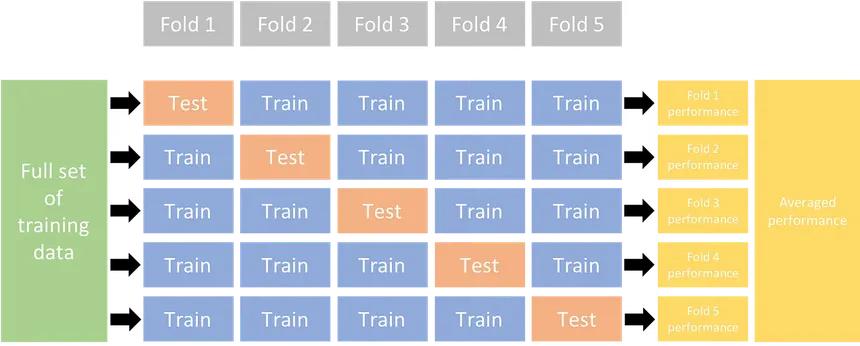

Deux découpages, deux usages. `cv` sert aux étapes exploratoires, où l'on situe simplement les modèles les uns par rapport aux autres. `cv_fiable` répète ce découpage et sert là où une décision se prend : quel modèle retenir, et à quel seuil. Dix mesures valent mieux que cinq pour départager des modèles proches.

`n_jobs=-1` répartit les plis sur tous les cœurs ; les forêts repassent à `n_jobs=1` pour ne pas se disputer les mêmes.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Dix mesures au lieu de cinq, la ou une decision se prend
cv_fiable = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

# Les forets parallelisent deja en interne. Si on parallelise aussi les plis,
# les deux niveaux se disputent les coeurs et le gain disparait : on laisse donc
# la parallelisation au niveau des plis, qui est de loin le plus rentable.
foret.set_params(modele__n_jobs=1)
arbres_extra.set_params(modele__n_jobs=1)

lignes = []
for nom, modele in modeles.items():
    # cv simple ici : aucune decision ne se prend a cette etape, elle sert a
    # situer les modeles les uns par rapport aux autres.
    r = cross_validate(modele, X_train, y_train, cv=cv, n_jobs=-1,
                       scoring=["f1", "roc_auc", "average_precision"])
    lignes.append({
        "modele": nom,
        "f1": round(r["test_f1"].mean(), 3),          # au seuil par defaut de 0.5
        "f1_ecart": round(r["test_f1"].std(), 3),
        "auc": round(r["test_roc_auc"].mean(), 3),
        "precision_moyenne": round(r["test_average_precision"].mean(), 3),
    })

comparaison = pl.DataFrame(lignes).sort("precision_moyenne", descending=True)
comparaison

modele,f1,f1_ecart,auc,precision_moyenne
str,f64,f64,f64,f64
"""super_learner""",0.06,0.023,0.792,0.301
"""logistique""",0.284,0.021,0.777,0.295
"""foret""",0.326,0.007,0.785,0.289
"""boosting""",0.321,0.016,0.771,0.271
"""arbres_extra""",0.316,0.021,0.772,0.256


***Journalisation de la comparaison***

Un run par modèle, tous étiquetés `etape=comparaison`. Le F1 est enregistré tel quel, au seuil par défaut : c'est la trace de ce qu'il vaut avant réglage.

In [ ]:
for ligne in lignes:
    nom = ligne["modele"]
    ## Démarrer un run MLflow
    with mlflow.start_run(run_name="comp-" + nom, tags=tags("comparaison", nom)):
        # Enregistrer les hyperparamètres du modèle
        mlflow.log_params({"variables": X_train.width,
                           "plis": cv_fiable.get_n_splits()})
        # Enregistrer la métrique
        mlflow.log_metrics({
            "f1_seuil_0.5": ligne["f1"],
            "f1_ecart": ligne["f1_ecart"],
            "auc": ligne["auc"],
            "precision_moyenne": ligne["precision_moyenne"],
        })

print(len(lignes), "runs enregistres | etape comparaison")

🏃 View run comp-boosting at: http://localhost:5000/#/experiments/10/runs/83e7a0eda1544cfe918a127a9fcc76f9
🧪 View experiment at: http://localhost:5000/#/experiments/10
🏃 View run comp-logistique at: http://localhost:5000/#/experiments/10/runs/f33b3287252342fca94353918e30ddbc
🧪 View experiment at: http://localhost:5000/#/experiments/10
🏃 View run comp-foret at: http://localhost:5000/#/experiments/10/runs/40e859a6ff3340b0bcbaeff5e33db64e
🧪 View experiment at: http://localhost:5000/#/experiments/10
🏃 View run comp-arbres_extra at: http://localhost:5000/#/experiments/10/runs/3ec732f7f52e40c6b68b50cb19a509bc
🧪 View experiment at: http://localhost:5000/#/experiments/10
🏃 View run comp-super_learner at: http://localhost:5000/#/experiments/10/runs/c5a3fa5408ab40ebab41889608b99831
🧪 View experiment at: http://localhost:5000/#/experiments/10
5 runs enregistres | etape comparaison


***Résultats***

Trois mesures, trois lectures.

Le **F1** combine la précision parmi les patients signalés, la part qui a réellement une bactériémie  et le rappel parmi les bactériémies réelles, la part détectée. C'est leur moyenne harmonique : il ne monte que si les deux montent. Mais il se calcule ici au seuil par défaut de 0,5, qui n'a aucune raison d'être le bon avec 8 % de positifs. À lire avec précaution.

L'**AUC** est la probabilité qu'un patient malade reçoive une note plus élevée qu'un patient sain tiré au hasard. Elle juge le classement sans dépendre d'un seuil, mais reste flatteuse quand les négatifs dominent.

La **précision moyenne** est l'aire sous la courbe précision-rappel, c'est-à-dire la précision moyennée sur tous les seuils possibles. Elle se concentre sur la classe rare : c'est la mesure la plus honnête ici, et le critère de l'optimisation qui suit.


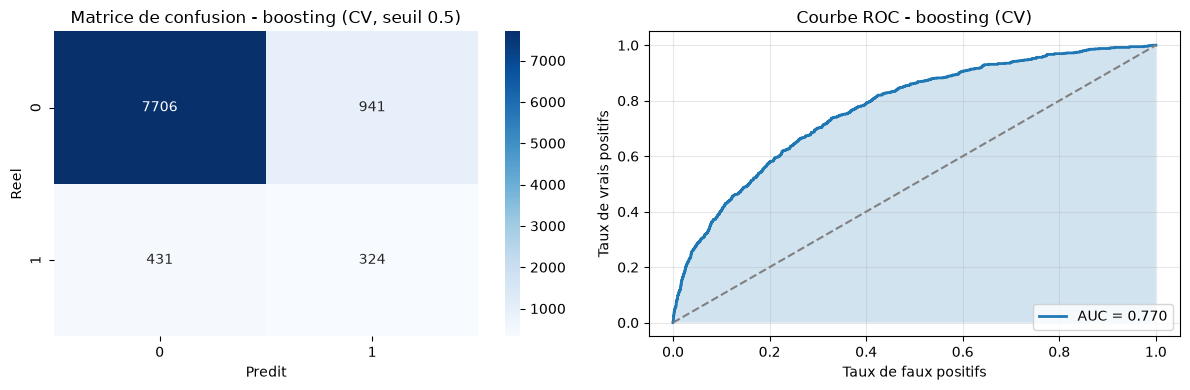

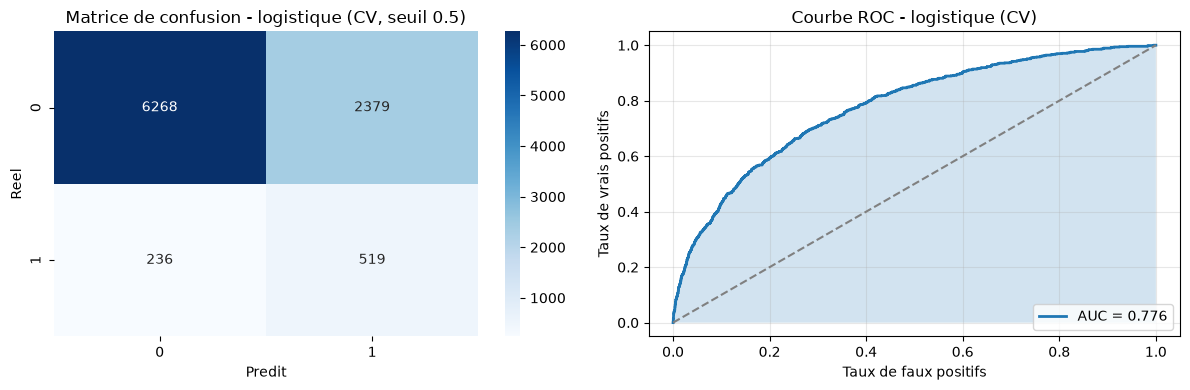

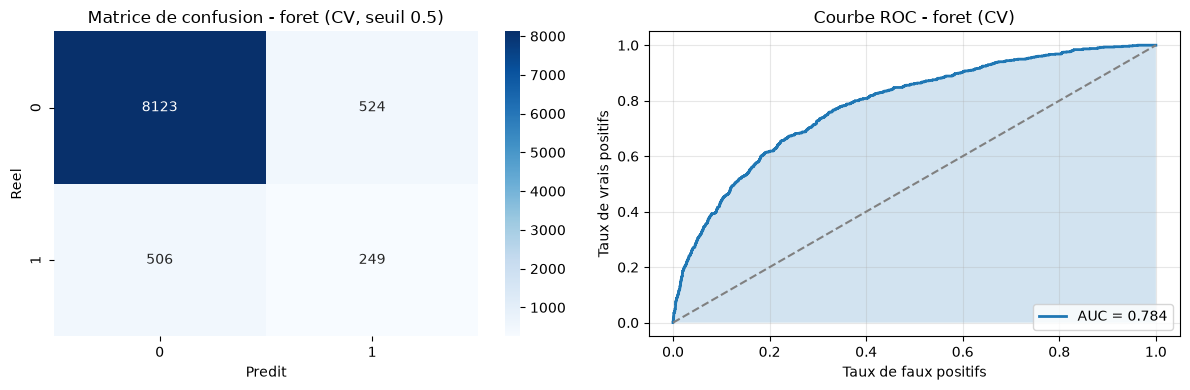

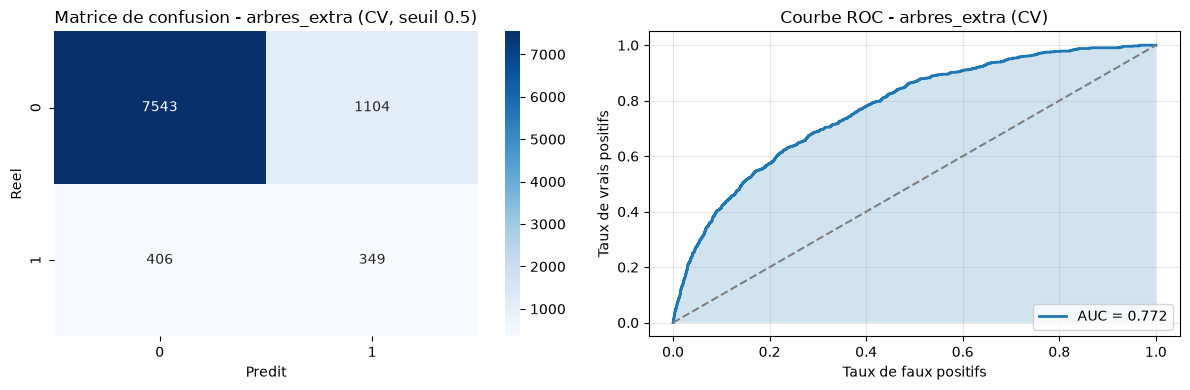

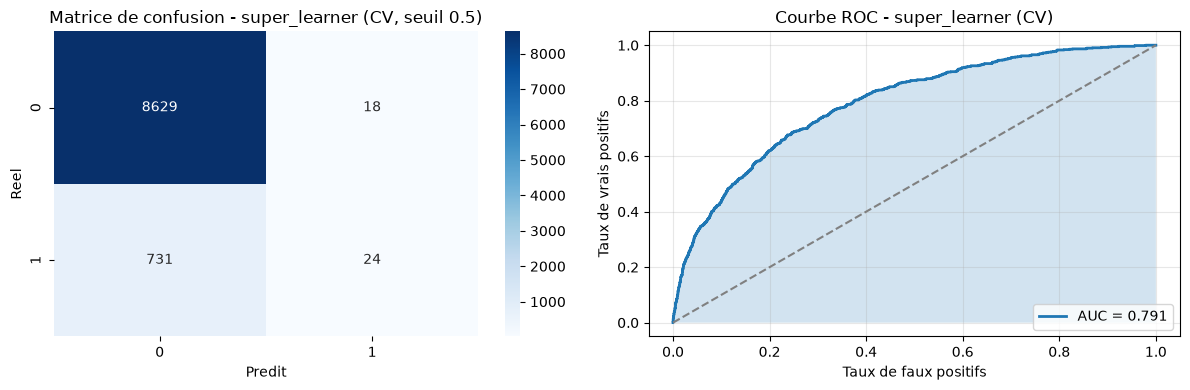

In [ ]:
# Probabilites hors echantillon : un patient est predit par un modele qui ne l'a pas vu.
# Elles decrivent les modeles AVANT optimisation : la section 9 les recalculera
# sur les modeles regles.
proba_cv = {
    nom: cross_val_predict(modele, X_train, y_train, cv=cv, n_jobs=-1,
                           method="predict_proba")[:, 1]
    for nom, modele in modeles.items()
}

for nom, proba in proba_cv.items():
    y_pred = (proba >= 0.5).astype(int)          # sans optimisation : seuil par defaut

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Matrice de confusion
    cm = confusion_matrix(y_train, y_pred)

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])

    axes[0].set_xlabel("Predit")
    axes[0].set_ylabel("Reel")
    axes[0].set_title(f"Matrice de confusion - {nom} (CV, seuil 0.5)")

    # Courbe ROC
    fpr, tpr, thresholds = roc_curve(y_train, proba)
    auc = roc_auc_score(y_train, proba)

    axes[1].plot(fpr, tpr, linewidth=2, label=f"AUC = {auc:.3f}")
    axes[1].plot([0, 1], [0, 1], "--", color="gray")
    axes[1].fill_between(fpr, tpr, alpha=0.2)

    axes[1].set_xlabel("Taux de faux positifs")
    axes[1].set_ylabel("Taux de vrais positifs")
    axes[1].set_title(f"Courbe ROC - {nom} (CV)")
    axes[1].legend(loc="lower right")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## 8. Optimisation des hyperparamètres

Jusqu'ici les modèles tournent avec leurs réglages par défaut.

[BayesSearchCV](https://scikit-optimize.github.io/stable/modules/generated/skopt.BayesSearchCV.html) fait une optimisation bayésienne : au lieu de tirer des combinaisons au hasard, il apprend des essais précédents et vise les zones prometteuses. `DeltaYStopper` l'arrête quand le score ne progresse plus.

Le super-learner n'est pas optimisé directement, ce serait trop coûteux : il est reconstruit à partir de ses composants une fois ceux-ci réglés.

***Les espaces de recherche***

In [ ]:
# Les bornes sont volontairement larges : une valeur retenue collee a une borne
# signale un espace trop etroit. max_depth ne figure pas dans les deux forets,
# c'est min_samples_leaf qui y regularise reellement.
espaces = {
    "boosting": {
        "learning_rate": Real(1e-3, 0.3, prior="log-uniform"),
        "max_iter": Integer(200, 1500),
        "max_leaf_nodes": Integer(5, 127),
        "min_samples_leaf": Integer(10, 500),
        "l2_regularization": Real(1e-3, 1e5, prior="log-uniform"),
    },
    "logistique": {
        "modele__C": Real(1e-6, 1e2, prior="log-uniform"),
    },
    "arbres_extra": {
        "modele__n_estimators": Integer(200, 1200),
        "modele__min_samples_leaf": Integer(1, 120),
        "modele__max_features": Categorical(["sqrt", "log2"]),
    },
    "foret": {
        "modele__n_estimators": Integer(200, 1200),
        "modele__min_samples_leaf": Integer(1, 120),
        "modele__max_features": Categorical(["sqrt", "log2"]),
        "modele__class_weight": Categorical(["balanced", "balanced_subsample"]),
    },
}

***La recherche***

Le critère est `average_precision`, pas le F1. Le F1 se mesure à un seuil fixé d'avance, alors que le seuil n'est réglé qu'à la section 9 : optimiser dessus reviendrait à juger les modèles sur une décision qui n'est pas encore prise.

La recherche est longue, elle n'est donc lancée qu'une fois. Les hyperparamètres sont enregistrés dans `models/`, sous un nom contenant une empreinte des bornes de l'espace : en modifier une seule relance la recherche automatiquement, sans numéro de version à maintenir.

`refit=False` : la section 9 réentraînera de toute façon.

In [ ]:
def empreinte(espaces: dict) -> str:
    """Empreinte de l'espace de recherche, calculee sur les bornes elles-memes.

    Changer une seule borne change l'empreinte, donc le nom du cache, donc
    relance la recherche. Plus de numero de version a incrementer a la main,
    et plus de risque de relire des hyperparametres trouves dans un autre espace.
    """
    lisible = {m: {k: repr(v) for k, v in sorted(d.items())}
               for m, d in sorted(espaces.items())}
    return hashlib.sha1(json.dumps(lisible, sort_keys=True).encode()).hexdigest()[:10]


# Le critere et l'empreinte de l'espace font partie du nom du cache : en changer
# l'un ou l'autre invalide le fichier precedent, sans suppression manuelle.
CRITERE = "average_precision"
ESPACE = empreinte(espaces)
CACHE = Path(f"../models/hyperparametres_{CRITERE}_{ESPACE}.joblib")
print("empreinte de l'espace :", ESPACE)

if CACHE.exists():
    trouve = joblib.load(CACHE)
    print("hyperparametres relus depuis", CACHE)
    print("supprimez ce fichier pour relancer une vraie recherche")
else:
    # n_jobs=-1 est sur la recherche, donc la foret passe a n_jobs=1 : sinon les deux
    # niveaux de parallelisme se disputent les coeurs et tout ralentit.
    foret.set_params(modele__n_jobs=1)

    trouve = {"params": {}, "resume": []}
    for nom, espace in espaces.items():
        reglages = {"n_iter": 40, "cv": cv, "n_jobs": -1}
        recherche = BayesSearchCV(
            estimator=modeles[nom],
            search_spaces=espace,
            scoring=CRITERE,
            refit=False,
            random_state=SEED,
            **reglages,
        )
        recherche.fit(X_train, y_train, callback=[DeltaYStopper(delta=0.001)])

        trouve["params"][nom] = dict(recherche.best_params_)
        # best_score_ suit CRITERE, donc on le compare a la precision moyenne de
        # la section 7 et non a son F1 : sinon les deux colonnes ne parlent pas
        # de la meme chose.
        trouve["resume"].append({
            "modele": nom,
            "ap_avant": comparaison.filter(pl.col("modele") == nom)["precision_moyenne"][0],
            "ap_apres": round(recherche.best_score_, 3),
            "essais": len(recherche.cv_results_["params"]),
        })
        print(nom, "->", dict(recherche.best_params_), flush=True)

    CACHE.parent.mkdir(exist_ok=True)
    joblib.dump(trouve, CACHE)

# On part de tous les modeles, puis on remplace ceux qui ont ete optimises :
# un modele absent de la recherche garde ainsi ses reglages par defaut au
# lieu de disparaitre de la suite du notebook.
meilleurs = dict(modeles)
for nom, p in trouve["params"].items():
    meilleurs[nom] = modeles[nom].set_params(**p)
pl.DataFrame(trouve["resume"])

empreinte de l'espace : 767f064912
hyperparametres relus depuis ..\models\hyperparametres_average_precision_767f064912.joblib
supprimez ce fichier pour relancer une vraie recherche


modele,ap_avant,ap_apres,essais
str,f64,f64,i64
"""boosting""",0.255,0.298,40
"""logistique""",0.294,0.297,21
"""arbres_extra""",0.257,0.263,40
"""foret""",0.288,0.29,40


***Journalisation de l'optimisation***

Un run par modèle, avec les hyperparamètres retenus en paramètres et le gain de précision moyenne en métriques. Le critère et la version de l'espace de recherche sont enregistrés aussi : sans eux, deux runs ne seraient pas comparables.

In [ ]:
for ligne in trouve["resume"]:
    nom = ligne["modele"]
    with mlflow.start_run(run_name="opt-" + nom, tags=tags("optimisation", nom)):
        mlflow.log_params(trouve["params"][nom])
        mlflow.log_params({"critere": CRITERE, "empreinte_espace": ESPACE})
        # Les bornes explorees, pour que deux runs d'espaces differents
        # soient comparables dans l'interface.
        mlflow.log_params({"espace_" + k: repr(v)
                           for k, v in espaces[nom].items()})
        mlflow.log_metrics({
            "precision_moyenne_avant": ligne["ap_avant"],
            "precision_moyenne_apres": ligne["ap_apres"],
            "essais": ligne["essais"],
        })

print(len(trouve["resume"]), "runs enregistres | etape optimisation")

🏃 View run opt-boosting at: http://localhost:5000/#/experiments/10/runs/a6cdf9317213430283b45c34b52e4fa6
🧪 View experiment at: http://localhost:5000/#/experiments/10
🏃 View run opt-logistique at: http://localhost:5000/#/experiments/10/runs/9d34848176c14ebaa45eb5badaa066aa
🧪 View experiment at: http://localhost:5000/#/experiments/10
🏃 View run opt-arbres_extra at: http://localhost:5000/#/experiments/10/runs/7b0d9a6b786e44ab8bda29a2e16cb9b9
🧪 View experiment at: http://localhost:5000/#/experiments/10
🏃 View run opt-foret at: http://localhost:5000/#/experiments/10/runs/1999108a15cf4e2f8dc5ade3ebdf8407
🧪 View experiment at: http://localhost:5000/#/experiments/10
4 runs enregistres | etape optimisation


***Le super-learner reconstruit***

Les quatre modèles réglés remplacent les modèles par défaut à l'intérieur de l'empilement, puis `modeles` est remplacé : tout ce qui suit travaille sur les modèles optimisés.

In [ ]:
meilleurs["super_learner"] = StackingClassifier(
    estimators=[(nom, meilleurs[nom])
                for nom in ["boosting", "logistique", "foret", "arbres_extra"]],
    final_estimator=LogisticRegression(max_iter=2000),
    cv=3,
    n_jobs=1,
)

modeles = meilleurs
print("modeles optimises :", list(modeles))

modeles optimises : ['boosting', 'logistique', 'foret', 'arbres_extra', 'super_learner']


## 9. Régler le seuil de décision

Un modèle renvoie une probabilité ; le passage à 0 ou 1 se fait par un seuil, fixé par défaut à 0,5. Avec 8 % de positifs, ce choix n'a aucune raison d'être le bon.

[TunedThresholdClassifierCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html) cherche le seuil qui maximise le F1 en validation croisée, pour ne pas le régler sur des probabilités surajustées.

Son intérêt : l'objet renvoyé est lui-même un classifieur, dont le `predict` applique déjà le seuil. Il n'y a donc aucun seuil à transporter jusqu'à `Predicts.py`.

In [ ]:
regles = {}
for nom, modele in modeles.items():
    regles[nom] = TunedThresholdClassifierCV(
        estimator=modele,
        scoring="f1",
        cv=cv_fiable,
        store_cv_results=True,   # garde la courbe F1 = f(seuil)
        n_jobs=-1,
    ).fit(X_train, y_train)

    print(nom, "-> seuil", round(regles[nom].best_threshold_, 3),
          "| F1", round(regles[nom].best_score_, 3), flush=True)

pl.DataFrame([
    {"modele": nom, "seuil_optimal": round(t.best_threshold_, 3),
     "f1_cv": round(t.best_score_, 3)}
    for nom, t in regles.items()
]).sort("f1_cv", descending=True)

boosting -> seuil 0.666 | F1 0.332
logistique -> seuil 0.689 | F1 0.337
foret -> seuil 0.537 | F1 0.336
arbres_extra -> seuil 0.241 | F1 0.328
super_learner -> seuil 0.205 | F1 0.352


modele,seuil_optimal,f1_cv
str,f64,f64
"""super_learner""",0.205,0.352
"""logistique""",0.689,0.337
"""foret""",0.537,0.336
"""boosting""",0.666,0.332
"""arbres_extra""",0.241,0.328


***Journalisation des seuils***

Un run par modèle. Le seuil et le F1 qu'il atteint sont les deux chiffres qui décident du modèle retenu.

In [ ]:
for nom, t in regles.items():
    with mlflow.start_run(run_name="seuil-" + nom, tags=tags("seuil", nom)):
        mlflow.log_metrics({"seuil_optimal": t.best_threshold_,
                            "f1_cv": t.best_score_})

print(len(regles), "runs enregistres | etape seuil")

🏃 View run seuil-boosting at: http://localhost:5000/#/experiments/10/runs/b3f9b2fa51914830a30a3a0bdcaf0d03
🧪 View experiment at: http://localhost:5000/#/experiments/10
🏃 View run seuil-logistique at: http://localhost:5000/#/experiments/10/runs/57eeda6d55064e90b4cc55c472de7c60
🧪 View experiment at: http://localhost:5000/#/experiments/10
🏃 View run seuil-foret at: http://localhost:5000/#/experiments/10/runs/6261da5824d64b50b02b814d834944f8
🧪 View experiment at: http://localhost:5000/#/experiments/10
🏃 View run seuil-arbres_extra at: http://localhost:5000/#/experiments/10/runs/0da51f5b992b4d17acb4b21bf74a8e53
🧪 View experiment at: http://localhost:5000/#/experiments/10
🏃 View run seuil-super_learner at: http://localhost:5000/#/experiments/10/runs/a93d27c2c5564d3cae0fb9a83102a8db
🧪 View experiment at: http://localhost:5000/#/experiments/10
5 runs enregistres | etape seuil


***Le F1 en fonction du seuil***

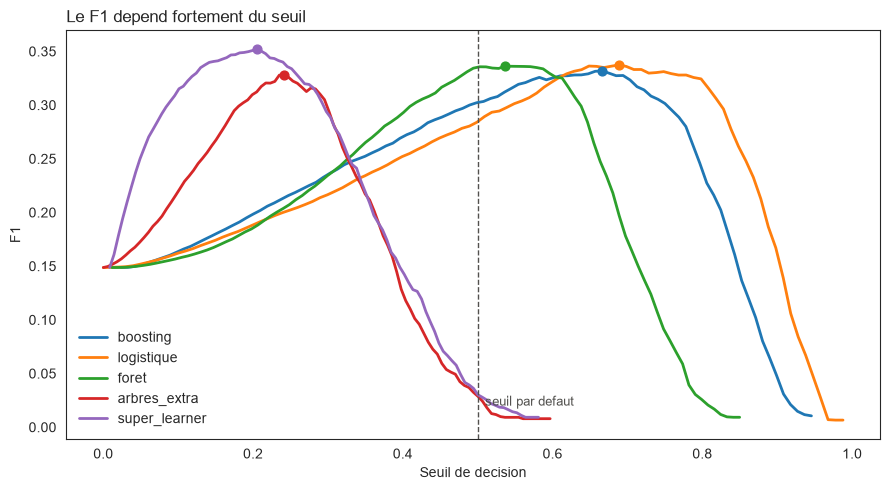

In [ ]:
sns.set_style("white")

plt.figure(figsize=(9, 5))
for nom, t in regles.items():
    plt.plot(t.cv_results_["thresholds"], t.cv_results_["scores"], label=nom, linewidth=2)
    plt.scatter(t.best_threshold_, t.best_score_, s=40, zorder=5)

plt.axvline(0.5, color="#52514e", linestyle="--", linewidth=1)
plt.text(0.51, 0.02, "seuil par defaut", fontsize=9, color="#52514e")
plt.xlabel("Seuil de decision")
plt.ylabel("F1")
plt.title("Le F1 depend fortement du seuil", fontsize=12, loc="left")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

***Quelles variables portent la décision***

Pour savoir si une variable compte vraiment, [permutation_importance](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html) en mélange les valeurs au hasard et regarde de combien le score chute. Si rien ne bouge, c'est que le modèle ne s'en servait pas. L'intérêt de cette méthode est qu'elle s'applique à n'importe quel modèle, y compris au super-learner.

Deux précautions s'imposent à la lecture. Le calcul porte sur les données d'entraînement, puisque le jeu de test ne doit servir qu'une seule fois : une variable que le modèle a mémorisée peut donc sembler plus utile qu'elle ne l'est. Et quand deux variables disent la même chose, mélanger l'une laisse l'autre disponible, si bien que toutes deux paraissent négligeables alors que l'information, elle, compte.

In [ ]:
# Le score utilise est la precision moyenne, comme pour l'optimisation :
# il ne depend d'aucun seuil.
nom_meilleur = max(regles, key=lambda n: regles[n].best_score_)

# .to_pandas() est indispensable : permutation_importance convertit en tableau
# numpy la colonne qu'il permute, et le ColumnTransformer, qui selectionne ses
# colonnes par leur nom, ne s'y retrouve plus. pandas arrive avec seaborn.
importances = permutation_importance(
    regles[nom_meilleur], X_train.to_pandas(), np.asarray(y_train),
    scoring="average_precision",
    n_repeats=3,
    max_samples=2000,        # borne le cout : le super-learner est lent a predire
    random_state=SEED,
    # Pas de parallelisme ici. permutation_importance envoie le modele DEJA
    # ENTRAINE a chaque processus ouvrier, ce qui est a la fois couteux et
    # fragile : c'est la que tombe le BrokenProcessPool. A la mesure, n_jobs=1
    # est deux fois et demie plus rapide que n_jobs=-1, le transfert du modele
    # coutant plus que le calcul reparti.
    n_jobs=1,
)

classement = pl.DataFrame({
    "variable": X_train.columns,
    "perte_moyenne": importances.importances_mean.round(4),
    "ecart": importances.importances_std.round(4),
}).sort("perte_moyenne", descending=True)

print("modele examine :", nom_meilleur)
classement.head(15)

c:\Users\Abdo\OneDrive\Documents\Projet\Julian Gode\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(
c:\Users\Abdo\OneDrive\Documents\Projet\Julian Gode\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(
c:\Users\Abdo\OneDrive\Documents\Projet\Julian Gode\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(
c:\Users\Abdo\OneDrive\Documents\Projet\Julian Gode\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(
c:\Users\Abdo\OneDrive\Documents\Projet\Julian Gode\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but Simp

modele examine : super_learner


variable,perte_moyenne,ecart
str,f64,f64
"""GLU""",0.1182,0.0073
"""AGE""",0.1071,0.0045
"""SODIUM""",0.0957,0.008
"""CHE""",0.0926,0.0036
"""CRP""",0.0906,0.0027
"""LDH""",0.0832,0.0027
"""MG""",0.0789,0.0047
"""NT""",0.0773,0.0031
"""ratio_crp_alb""",0.0768,0.0035


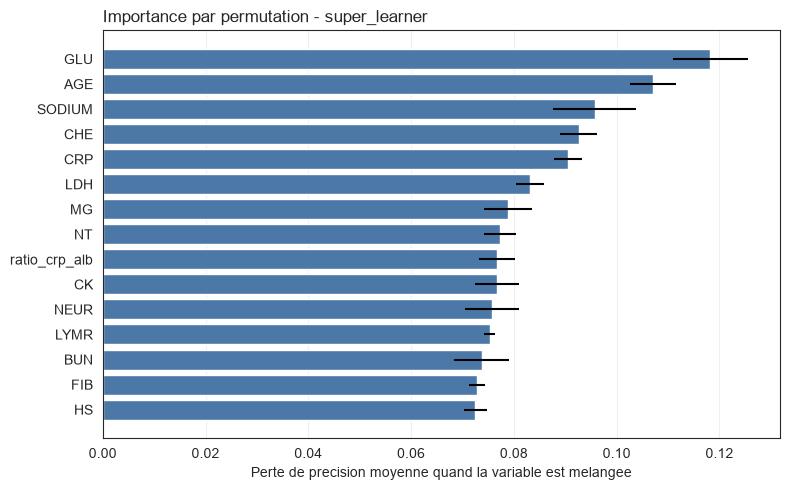

In [ ]:
top = classement.head(15).reverse()

plt.figure(figsize=(8, 5))
plt.barh(top["variable"], top["perte_moyenne"], xerr=top["ecart"], color="#4c78a8")
plt.xlabel("Perte de precision moyenne quand la variable est melangee")
plt.title(f"Importance par permutation - {nom_meilleur}", fontsize=12, loc="left")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Évaluation finale sur le jeu de test

`TunedThresholdClassifierCV` a déjà réentraîné le modèle retenu sur tout l'entraînement, seuil compris. Il ne reste donc qu'à l'évaluer **une seule fois** sur le jeu de test.

C'est cette valeur qui estime la performance attendue le jour du rendu.

In [ ]:
meilleur = max(regles, key=lambda n: regles[n].best_score_)
modele_final = regles[meilleur]          # deja entraine, seuil inclus
print("modele retenu :", meilleur, "| seuil :", round(modele_final.best_threshold_, 3))

pred_test = modele_final.predict(X_test)                    # le seuil est applique ici
proba_test = modele_final.predict_proba(X_test)[:, 1]

pl.DataFrame({
    "metrique": ["f1", "precision", "rappel", "auc"],
    "test": [
        round(f1_score(y_test, pred_test), 3),
        round(precision_score(y_test, pred_test), 3),
        round(recall_score(y_test, pred_test), 3),
        round(roc_auc_score(y_test, proba_test), 3),
    ],
})

modele retenu : super_learner | seuil : 0.205


metrique,test
str,f64
"""f1""",0.338
"""precision""",0.304
"""rappel""",0.381
"""auc""",0.775


                    precision    recall  f1-score   support

pas de bacteriemie       0.94      0.92      0.93      2162
       bacteriemie       0.30      0.38      0.34       189

          accuracy                           0.88      2351
         macro avg       0.62      0.65      0.64      2351
      weighted avg       0.89      0.88      0.89      2351



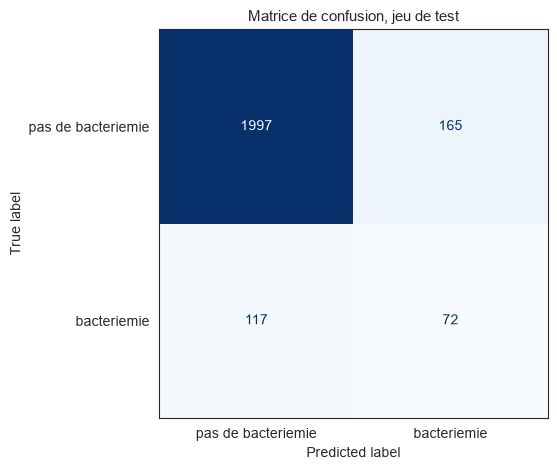

In [ ]:
print(classification_report(y_test, pred_test, target_names=["pas de bacteriemie", "bacteriemie"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["pas de bacteriemie", "bacteriemie"], colorbar=False, cmap="Blues"
)
plt.title("Matrice de confusion, jeu de test", fontsize=11)
plt.tight_layout()
fig_confusion = plt.gcf()      # conservee pour MLflow
plt.show()

***Où se placent les erreurs***

Les deux densités montrent comment le super-learner note les patients réellement négatifs et réellement positifs. Les points alignés sur l'axe sont les patients du jeu de test, séparés selon le quadrant de la matrice de confusion.

La ligne verticale est le seuil retenu : tout ce qui est à sa droite est prédit positif. Le recouvrement des deux densités montre du même coup pourquoi la précision reste modeste , aucun seuil ne peut les séparer proprement.

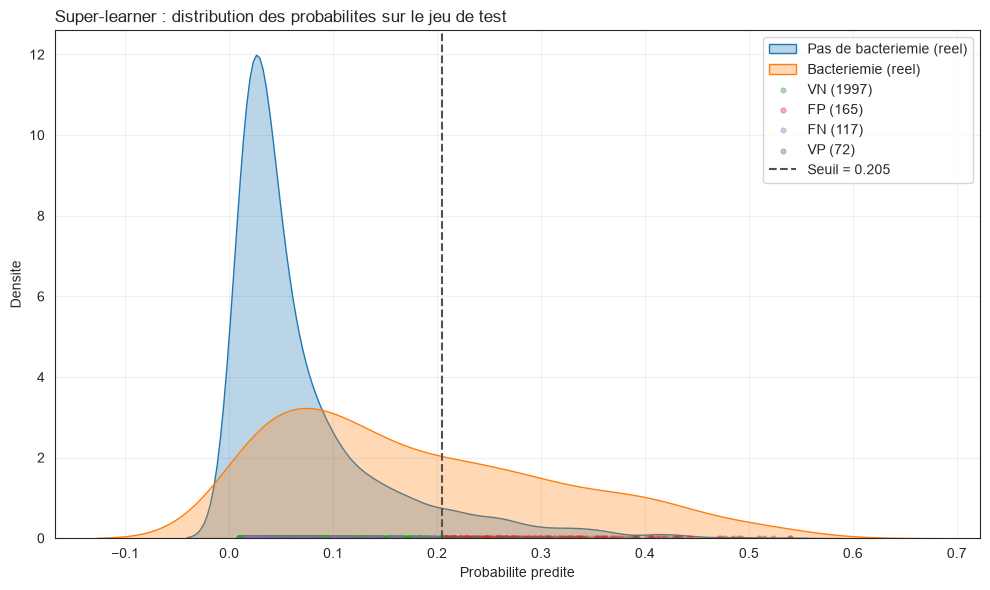

In [ ]:
# Distribution des probabilites du super-learner sur le jeu de test
super_regle = regles["super_learner"]

proba_sl = super_regle.predict_proba(X_test)[:, 1]
pred_sl = super_regle.predict(X_test)
seuil_sl = super_regle.best_threshold_
y_vrai = np.asarray(y_test)

masques = {
    "VN": (y_vrai == 0) & (pred_sl == 0),
    "FP": (y_vrai == 0) & (pred_sl == 1),
    "FN": (y_vrai == 1) & (pred_sl == 0),
    "VP": (y_vrai == 1) & (pred_sl == 1),
}

plt.figure(figsize=(10, 6))

sns.kdeplot(proba_sl[y_vrai == 0], label="Pas de bacteriemie (reel)", fill=True, alpha=0.3)
sns.kdeplot(proba_sl[y_vrai == 1], label="Bacteriemie (reel)", fill=True, alpha=0.3)

for nom_masque, m in masques.items():
    plt.scatter(proba_sl[m], np.zeros(m.sum()), s=12, alpha=0.35,
                label=f"{nom_masque} ({m.sum()})")

plt.axvline(seuil_sl, linestyle="--", color="#52514e", label=f"Seuil = {seuil_sl:.3f}")

plt.xlabel("Probabilite predite")
plt.ylabel("Densite")
plt.title("Super-learner : distribution des probabilites sur le jeu de test",
          fontsize=12, loc="left")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
fig_distribution = plt.gcf()   # conservee pour MLflow
plt.show()

## 11. Enregistrement du modèle retenu dans MLflow

Le run final rassemble tout ce qui caractérise le modèle livré : ses paramètres, ses quatre métriques sur le jeu de test, les deux figures, le rapport de classification, le classement des variables, et le modèle lui-même avec sa signature.

`infer_signature` déduit des exemples le type et le nom des colonnes attendues. C'est ce qui permettra de recharger le modèle et de vérifier qu'on lui donne la bonne structure.

In [ ]:
with mlflow.start_run(run_name="final-" + meilleur, tags=tags("test", meilleur)):
    mlflow.log_params({
        "modele": meilleur,
        "seuil": round(float(modele_final.best_threshold_), 4),
        "variables": X_train.width,
        "ecartees_du_lineaire": ",".join(REDONDANTES_LINEAIRE),
        "derivees_retirees": ",".join(DERIVEES),
    })
    mlflow.log_metrics({
        "f1": f1_score(y_test, pred_test),
        "precision": precision_score(y_test, pred_test),
        "rappel": recall_score(y_test, pred_test),
        "auc": roc_auc_score(y_test, proba_test),
    })

    mlflow.log_figure(fig_confusion, "matrice_confusion.png")
    mlflow.log_figure(fig_distribution, "distribution_probabilites.png")

    mlflow.log_text(
        classification_report(y_test, pred_test,
                              target_names=["pas de bacteriemie", "bacteriemie"]),
        "classification_report.txt")
    mlflow.log_text(classement.write_csv(), "importance_permutation.csv")

    # infer_signature attend du pandas, d'ou les conversions
    exemple = X_train.head(100)
    # MLflow 3 enregistre par defaut avec skops, qui refuse de recharger les
    # structures d'arbres et les scorers sans les declarer de confiance une par
    # une. cloudpickle n'a pas cette contrainte : le modele vient de ce notebook,
    # la question de la confiance ne se pose pas.
    mlflow.sklearn.log_model(
        modele_final,
        name="modele_bacteriemie",
        serialization_format="cloudpickle",
        signature=infer_signature(exemple.to_pandas(), modele_final.predict(exemple)),
        input_example=X_train.head(5).to_pandas(),
    )

print("run final enregistre | modele :", meilleur)

c:\Users\Abdo\OneDrive\Documents\Projet\Julian Gode\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/19 17:23:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which 

🏃 View run final-super_learner at: http://localhost:5000/#/experiments/10/runs/6c8ffce30c4f43eb967b70e99c594267
🧪 View experiment at: http://localhost:5000/#/experiments/10
run final enregistre | modele : super_learner


## 12. Réentraînement et sauvegarde

Le modèle retenu est réentraîné sur **toutes** les données, entraînement et test réunis : plus de données, meilleur modèle. Le seuil est retrouvé au passage, par la même validation croisée, sur ce jeu complet.

`joblib` n'enregistre plus qu'un seul objet : le classifieur porte son seuil en lui, donc `Predicts.py` n'a qu'à appeler `predict`.

In [ ]:
X_tout = pl.concat([X_train, X_test])
y_tout = np.concatenate([y_train, y_test])

modele_final.fit(X_tout, y_tout)         # reentraine le modele et rejoue la recherche de seuil

joblib.dump({"modele": modele_final, "colonnes": X_tout.columns},
            "../models/modele_bacteriemie.joblib")

print("enregistre : models/modele_bacteriemie.joblib",
      "| seuil :", round(modele_final.best_threshold_, 3))

enregistre : models/modele_bacteriemie.joblib | seuil : 0.222


## 13. Conclusions

### Le modèle retenu

Le super-learner, au seuil de 0,205.

| Mesure sur le jeu de test | Valeur |
|---|---|
| F1 | **0,338** |
| Précision | 0,304 |
| Rappel | 0,381 |
| AUC | 0,775 |

Parmi les patients signalés, environ trois sur dix ont réellement une bactériémie, contre huit sur cent dans la population de départ. Le modèle en détecte près de quatre sur dix.


### Les limites

Le plafond vient des données, pas des modèles. Les deux classes se recouvrent massivement, parce que tous ces patients étaient déjà suspects d'infection : il n'y a aucun sujet sain dans le jeu de données.

